In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report

from scipy import stats

# Helper Functions

In [12]:
def get_feature_types(df, target_col='Attack Type'):

    numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = df.select_dtypes(include=['object']).columns.tolist()

    # Remove target column if present
    if target_col in numeric_features:
        numeric_features.remove(target_col)
    if target_col in categorical_features:
        categorical_features.remove(target_col)

    return numeric_features, categorical_features

In [13]:
def correlation_analysis(df, numeric_features, threshold=0.85):

    # Calculate correlation matrix (using representative sample if dataset > 150,000 for high efficiency)
    if len(df) > 150000:
        sample_df = df[numeric_features].sample(150000, random_state=42)
    else:
        sample_df = df[numeric_features]
    corr_matrix = sample_df.corr()

    # Plot correlation heatmap
    plt.figure(figsize=(20, 20))
    sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, linewidth=0.5)
    plt.title('Feature Correlation Heatmap')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.show()

    # Identify highly correlated features
    high_corr = np.where(np.abs(corr_matrix) > threshold)
    high_corr = [(corr_matrix.index[x], corr_matrix.columns[y], corr_matrix.iloc[x, y])
                for x, y in zip(*high_corr) if x != y and x < y]

    return high_corr

In [14]:
def analyze_variance_homogeneity(df, numeric_features, target_col='Attack Type'):
    
    results_levene = {}
    # Sample if dataset is very large to compute Levene's test reliably and efficiently
    sample_df = df.sample(min(len(df), 250000), random_state=42) if len(df) > 250000 else df
    
    for feature in numeric_features:
        # Group data by y and filter out groups with zero values
        groups = [group[feature].dropna().values for name, group in sample_df.groupby(target_col)
                if not group[feature].dropna().empty]
        
        # Filter out groups that contain only zero values or have zero variance
        groups = [group for group in groups if len(group) > 0 and np.any(group != 0) and np.var(group) > 0]
        
        # Check if there are at least two groups with valid data
        if len(groups) < 2:
            print(f"Not enough valid groups to perform Levene's test for feature: {feature}")
            continue  # Skip this feature if not enough valid groups

        # Perform Levene's Test
        stat_levene, p_value_levene = stats.levene(*groups)
        results_levene[feature] = {'Statistic': stat_levene, 'p-value': p_value_levene}

    return results_levene

In [15]:
def analyze_feature_importance(df, numeric_features, target_col='Attack Type'):
    h_scores = {}
    # Sample if dataset is very large to compute Kruskal-Wallis test reliably and efficiently
    sample_df = df.sample(min(len(df), 250000), random_state=42) if len(df) > 250000 else df
    
    for feature in numeric_features:
        # Group data by y and perform the Kruskal-Wallis test
        groups = [group[feature].dropna().values for name, group in sample_df.groupby(target_col)]
        h_stat, p_val = stats.kruskal(*groups)
        h_scores[feature] = {'H-statistic': h_stat, 'p-value': p_val}

    # Create a DataFrame from the results
    h_scores_df = pd.DataFrame.from_dict(h_scores, orient='index')
    h_scores_df = h_scores_df.sort_values('H-statistic', ascending=False)

    # Plotting H-statistics
    plt.figure(figsize=(18, 10))
    plt.bar(range(len(h_scores_df)), h_scores_df['H-statistic'], color='skyblue')
    plt.xticks(range(len(h_scores_df)), h_scores_df.index, rotation=90)
    plt.title('Feature Importance based on H-statistic (Kruskal-Wallis Test)')
    plt.xlabel('Features')
    plt.ylabel('H-statistic')
    plt.tight_layout()
    plt.show()

    return h_scores_df


In [16]:
def analyze_feature_importance_rf(df, numeric_features, target_col='Attack Type'):

    # Hyperparameter settings
    hyperparameters = {
        'n_estimators': 150,    # Number of trees
        'max_depth': 30,        # Limit tree depth
        'random_state': 42,     # For reproducibility
        'n_jobs': -1            # Use all available cores
    }

    # Prepare the data (using representative sample if dataset > 250,000 for fast robust training)
    sample_df = df.sample(min(len(df), 250000), random_state=hyperparameters['random_state']) if len(df) > 250000 else df
    X = sample_df[numeric_features]
    y = sample_df[target_col]

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=hyperparameters['random_state'], stratify=y)

    # Create the Random Forest model with specified hyperparameters
    rf = RandomForestClassifier(**hyperparameters)

    # Fit the model on the training set
    rf.fit(X_train, y_train)

    # Cross-validation on the training set
    cv_scores = cross_val_score(rf, X_train, y_train, cv=5, n_jobs=-1)
    print(f'Cross-Validation Score: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}')

    # Predict on test set
    y_pred = rf.predict(X_test)

    # Feature importances
    importances = rf.feature_importances_
    feature_importance_df = pd.DataFrame({'Feature': numeric_features, 'Importance': importances})
    feature_importance_df = feature_importance_df.sort_values('Importance', ascending=False)

    # Confusion matrix
    rf_labels = rf.classes_
    cm = confusion_matrix(y_test, y_pred)

    # Calculate test scores
    report = classification_report(y_test, y_pred, target_names=rf_labels)
    print("\nClassification Report:\n")
    print(report, end='\n\n')

    # Plot feature importances
    plt.figure(figsize=(18, 12))
    plt.bar(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
    plt.ylabel('Importance')
    plt.xlabel('Features')
    plt.title('Feature Importance from Random Forest')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    return feature_importance_df, cm, rf_labels, cv_scores


In [17]:
def calculate_outliers_percentage(df):

    outlier_percentages = {}  # empty dictionary to store outlier percentages

    for column in df.columns:
        Q1 = df[column].quantile(0.25)  # first quartile (Q1) for the column
        Q3 = df[column].quantile(0.75)  # third quartile (Q3) for the column
        IQR = Q3 - Q1  # Interquartile Range (IQR)

        lower_bound = Q1 - 1.5 * IQR  # lower bound for outliers
        upper_bound = Q3 + 1.5 * IQR  # upper bound for outliers

        # Identify outliers in the column
        outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

        # Calculate the percentage of outliers for the column
        outlier_percentage = len(outliers) / len(df) * 100

        # Store the outlier percentage in the dictionary
        outlier_percentages[column] = outlier_percentage

    return outlier_percentages

# 1. Initial Exploration

## 1.1. Loading the Dataset

In [18]:
dfs = []

# Locate dataset directory (supports local workspace TrafficLabelling, relative paths, or Kaggle)
data_candidates = [
    'TrafficLabelling',
    os.path.join('..', 'TrafficLabelling'),
    os.path.join(os.getcwd(), 'TrafficLabelling'),
    '/kaggle/input/'
]
data_dir = next((d for d in data_candidates if os.path.exists(d)), 'TrafficLabelling')
print(f"Loading CICIDS2017 dataset from: {os.path.abspath(data_dir)}")

# Find all CSV files in the dataset directory
csv_files = sorted(glob.glob(os.path.join(data_dir, '**', '*.csv'), recursive=True) or glob.glob(os.path.join(data_dir, '*.csv')))

# Load each CSV file
for filename in csv_files:
    d = pd.read_csv(filename, encoding='latin1', low_memory=False)
    d.columns = d.columns.str.strip()  # Strip leading and trailing whitespace from column names
    d = d.dropna(how='all')            # Drop fully empty trailing rows
    dfs.append(d)
    print(f"Loaded {os.path.basename(filename):55s} -> {d.shape[0]:>8,} rows, {d.shape[1]} columns")


Loading CICIDS2017 dataset from: d:\RATE LIMITER\TrafficLabelling
Loaded Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv        ->  225,745 rows, 85 columns
Loaded Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv    ->  286,467 rows, 85 columns
Loaded Friday-WorkingHours-Morning.pcap_ISCX.csv               ->  191,033 rows, 85 columns
Loaded Monday-WorkingHours.pcap_ISCX.csv                       ->  529,918 rows, 85 columns
Loaded Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ->  288,602 rows, 85 columns
Loaded Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  ->  170,366 rows, 85 columns
Loaded Tuesday-WorkingHours.pcap_ISCX.csv                      ->  445,909 rows, 85 columns
Loaded Wednesday-workingHours.pcap_ISCX.csv                    ->  692,703 rows, 85 columns


In [19]:
# Data dimensions of each individual dataset
for i, d in enumerate(dfs, start=1):
    rows, cols = d.shape
    print(f'df{i} -> {rows:,} rows, {cols} columns')

df1 -> 225,745 rows, 85 columns
df2 -> 286,467 rows, 85 columns
df3 -> 191,033 rows, 85 columns
df4 -> 529,918 rows, 85 columns
df5 -> 288,602 rows, 85 columns
df6 -> 170,366 rows, 85 columns
df7 -> 445,909 rows, 85 columns
df8 -> 692,703 rows, 85 columns


## 1.2. Merging the DataFrames

As noted by Panigrahi and Borah (2018), a typical IDS should be able to handle different types of attacks. Since the CICIDS2017 dataset is divided into eight files containing various attack data, these files should be merged into a single cohesive unit.

In [20]:
# Concatenate all DataFrames into a single DataFrame
data = pd.concat(dfs, axis=0, ignore_index=True)

# Deleting DataFrames after merging to free memory
for df in dfs: del df
del dfs

# Remove non-flow metadata identifiers if present to avoid data leakage and keep pure network traffic flow features
id_cols = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Timestamp', 'Protocol']
data.drop(columns=[col for col in id_cols if col in data.columns], inplace=True)

print(f"Dataset shape after merging and cleaning network identifiers: {data.shape}")


Dataset shape after merging and cleaning network identifiers: (2830743, 79)


## 1.3. Data Overview

In [21]:
# Display the first few rows
data.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865.0,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
1,55054.0,109.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
2,55055.0,52.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
3,46236.0,34.0,1.0,1.0,6.0,6.0,6.0,6.0,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
4,54863.0,3.0,2.0,0.0,12.0,0.0,6.0,6.0,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN


In [12]:
# Display 10 random rows
data.sample(n=10, random_state=42)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
746827,443,20829,1,1,0,0,0,0,0.000000,0.000000,...,20,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
946912,80,1413228,3,5,26,11601,20,0,8.666667,10.263203,...,20,0.000000,0.000000,0,0,0.0,0.00000,0,0,DDoS
2216843,80,99951883,9,7,317,11595,317,0,35.222222,105.666667,...,32,999.000000,0.000000,999,999,99900000.0,0.00000,99900000,99900000,DoS Hulk
699389,80,12984169,9,11,10081,3626,3445,0,1120.111111,1452.563720,...,20,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
1170268,80,116017190,16,14,520,802,436,0,32.500000,107.610408,...,20,30442.181818,22653.805702,98745,23484,9998871.0,16434.76758,10012179,9950666,BENIGN
800686,53,226,2,2,46,46,23,23,23.000000,0.000000,...,32,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
1434488,53,63936,1,1,49,161,49,49,49.000000,0.000000,...,32,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
1968368,443,63405,5,4,121,3110,121,0,24.200000,54.112845,...,32,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
934343,443,6310806,54,94,2958,170879,517,0,54.777778,142.380260,...,32,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN
693547,53,193,2,2,68,100,34,34,34.000000,0.000000,...,32,0.000000,0.000000,0,0,0.0,0.00000,0,0,BENIGN


In [22]:
# Get dataset dimensions
print(f"Dataset Dimensions: {data.shape}")

Dataset Dimensions: (2830743, 79)


In [23]:
# Display data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             float64
 1   Flow Duration                float64
 2   Total Fwd Packets            float64
 3   Total Backward Packets       float64
 4   Total Length of Fwd Packets  float64
 5   Total Length of Bwd Packets  float64
 6   Fwd Packet Length Max        float64
 7   Fwd Packet Length Min        float64
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        float64
 11  Bwd Packet Length Min        float64
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 float64
 19  

By checking the data types, it is safe to assume the dataset countains only metric features, considering 'Label' as 'y' (the only categorical column).

In [24]:
# Checking for missing values
missing_values = data.isna().sum()
missing_percentage = (missing_values / len(data)) * 100

# Printing columns with missing values
for column, count in missing_values.items():
    if count != 0:
        print(f"Column '{column}' has {count} missing values, which is {missing_percentage[column]:.2f}% of the total")

Column 'Flow Bytes/s' has 1358 missing values, which is 0.05% of the total


The number of missing values may initially seem irrelevant; however, we can decide on the approach after further analysis.

# 2. Data Cleaning

In [ ]:
# Removal of leading/trailing whitespace
col_names = {col: col.strip() for col in data.columns}
data.rename(columns=col_names, inplace=True)

# Sanitize Label strings (handle non-ascii characters such as \x96, \ufffd, and excessive whitespace)
data['Label'] = (data['Label'].astype(str)
                .str.replace('\ufffd', '-', regex=False)
                .str.replace('\x96', '-', regex=False)
                .str.replace('–', '-', regex=False)
                .str.replace(r'\s+', ' ', regex=True)
                .str.strip())


## 2.1. Duplicates and Infinite

In [26]:
# Checking and counting duplicates
duplicates = data.duplicated()
duplicate_count = duplicates.sum()

# Output results
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 308218


Removing duplicates from a dataset is often considered safe and beneficial as it enhances data integrity, improves statistical accuracy, increases efficiency, and simplifies analysis.

In [27]:
# Removal of duplicates
data = data.drop_duplicates(keep='first')
del duplicates
data.shape

(2522525, 79)

The same can be done for columns

In [28]:
# Identify columns with identical data
identical_columns = {}
columns = data.columns
list_control = columns.copy().tolist()

# Compare each pair of columns
for col1 in columns:
    for col2 in columns:
        if col1 != col2:
            if data[col1].equals(data[col2]):
                if (col1 not in identical_columns) and (col1 in list_control):
                    identical_columns[col1] = [col2]
                    list_control.remove(col2)
                elif (col1 in identical_columns) and (col1 in list_control):
                    identical_columns[col1].append(col2)
                    list_control.remove(col2)

# Print the result
if identical_columns:
    print("Identical columns found:")
    for key, value in identical_columns.items():
        print(f"'{key}' is identical to {value}")
else: print("No identical columns found.")

Identical columns found:
'Total Fwd Packets' is identical to ['Subflow Fwd Packets']
'Total Backward Packets' is identical to ['Subflow Bwd Packets']
'Fwd PSH Flags' is identical to ['SYN Flag Count']
'Bwd PSH Flags' is identical to ['Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
'Fwd URG Flags' is identical to ['CWE Flag Count']
'Fwd Header Length' is identical to ['Fwd Header Length.1']


In [29]:
# Removing the columns with duplicated values
for key, value in identical_columns.items():
    data.drop(columns=value, inplace=True)

In [30]:
print(data.columns)
data.shape

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length',
       'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length',
       'Max Packet Length', 'Packet Length Mean', 'Packet Length Std',
       'Packet Length Variance', 'FIN Flag Count', 'RST Flag Count',
       'PSH Flag C

(2522525, 67)

In [22]:
# Checking for infinite values
num_columns = data.select_dtypes(include = np.number).columns
has_infinite = np.isinf(data[num_columns]).sum()
print(has_infinite[has_infinite > 0])

Flow Bytes/s      1211
Flow Packets/s    1564
dtype: int64


Removing infinite values is typically safe and beneficial, as it enhances data integrity, ensures statistical accuracy, aids in proper model training, and clarifies insights.

In [31]:
# Treating infinite values
data.replace([np.inf, -np.inf], np.nan, inplace=True)

# Ensure numeric features are converted to numeric data types
num_cols = [c for c in data.columns if c != 'Label']
data[num_cols] = data[num_cols].apply(pd.to_numeric, errors='coerce')


## 2.1. Missing Values

There are different approaches to dealing with missing values. The first step in identifying how to proceed is to understand their impact on the dataset. Here, we will do that by analyzing the y column (Label).

In [32]:
# Attack counts
attack_counts = data['Label'].value_counts().reset_index()
attack_counts.columns = ['Attack Type', 'Number of Occurrences']

# Duplicating the df and dropping rows with missing values
data_no_na = data.dropna()

# Counting the total number of occurrences of each attack after dropping
occurrences_nonull = data_no_na['Label'].value_counts().reset_index()
occurrences_nonull.columns = ['Attack Type', 'Occurrences w/o Null Rows']

# Merging the DataFrames
attack_counts = attack_counts.merge(occurrences_nonull, on='Attack Type', how='left')

# Calculating the difference
attack_counts['Abs Difference'] = attack_counts['Number of Occurrences'] - attack_counts['Occurrences w/o Null Rows']
attack_counts['Difference %'] = ((attack_counts['Abs Difference'] * 100) / attack_counts['Number of Occurrences']).round(2)

# Visualization
attack_counts

,Attack Type,Number of Occurrences,Occurrences w/o Null Rows,Abs Difference,Difference %
0,BENIGN,2096647,2095220,1427,0.07
1,DoS Hulk,172849,172846,3,0.00
2,DDoS,128016,128014,2,0.00
3,PortScan,90819,90694,125,0.14
4,DoS GoldenEye,10286,10286,0,0.00
5,FTP-Patator,5933,5931,2,0.03
6,DoS slowloris,5385,5385,0,0.00
7,DoS Slowhttptest,5228,5228,0,0.00
8,SSH-Patator,3219,3219,0,0.00
9,Bot,1953,1948,5,0.26


In [33]:
# Cleaning up
del data_no_na

# Evaluating percentage of missing values per column
threshold = 10
missing_percentage = (data.isnull().sum() / len(data)) * 100

# Filter columns with missing values over the threshold
high_missing_cols = missing_percentage[missing_percentage > threshold]

# Print columns with high missing percentages
if len(high_missing_cols) > 0:
    print(f'The following columns have over {threshold}% of missing values:')
    print(high_missing_cols)
else:
    print('There are no columns with missing values greater than the threshold')

There are no columns with missing values greater than the threshold


The analysis of missing values across the dataset suggests that missing values are not heavily concentrated in any single column and that the dataset can tolerate row-wise removal without significant impact.

In [34]:
row_missing_percentage = (data.isna().sum(axis=1) / data.shape[1]) * 100
print(row_missing_percentage.describe())

missing_rows = data.isna().any(axis=1).sum()
print(f'\nTotal rows with missing values: {missing_rows}')

count    2.522525e+06
mean     1.850787e-03
std      7.430555e-02
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.985075e+00
dtype: float64

Total rows with missing values: 1564


Following previous studies, such as Panigrahi and Borah (2018), and considering the minimal impact of removing rows with missing values (concentrated on the Benign class), we will proceed to drop these rows from the DataFrame.

In [35]:
# Dropping missing values
data = data.dropna()
print(f'Dataset shape after row-wise removal: {data.shape}')

Dataset shape after row-wise removal: (2520961, 67)


## 2.2. Data-Driven Feature Selection

The idea here is to perform a straightforward manual feature selection process that focuses on examining the dataset critically.

In [36]:
# Check for numeric columns that contain only a single unique value, indicating no diversity in values.
# Such columns contribute no useful information to the analysis and may be candidates for removal.
only_unique_cols = []
for col in data.columns:
    if len(data[col].unique()) == 1:
        only_unique_cols.append(col)
        print(col)

print(f'\nThe number of columns with only one unique values is: {len(only_unique_cols)}')

Bwd PSH Flags

The number of columns with only one unique values is: 1


Columns with only a single unique value can typically be removed from the dataset before training machine learning models without risk of loss of relevant information.

In [37]:
# Dropping the columns with only one unique value
data.drop(only_unique_cols, axis=1, inplace=True)
del only_unique_cols

In [38]:
# Checking the new shape after cleaning
data.shape

(2520961, 66)

## 2.3. Grouping/ Removing Attack Types

### 2.3.1. Grouping attack types

In [39]:
# Mapping the attacks to the new group
group_mapping = {
    'BENIGN': 'Normal Traffic',
    'DoS Hulk': 'DoS',
    'DDoS': 'DDoS',
    'PortScan': 'Port Scanning',
    'DoS GoldenEye': 'DoS',
    'FTP-Patator': 'Brute Force',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
    'SSH-Patator': 'Brute Force',
    'Bot': 'Bots',
    'Web Attack - Brute Force': 'Web Attacks',
    'Web Attack - XSS': 'Web Attacks',
    'Web Attack - Sql Injection': 'Web Attacks',
    'Web Attack  Brute Force': 'Web Attacks',
    'Web Attack  XSS': 'Web Attacks',
    'Web Attack  Sql Injection': 'Web Attacks',
    'Infiltration': 'Infiltration',
    'Heartbleed': 'Miscellaneous'
}

# Map to new group column
data['Attack Type'] = data['Label'].map(group_mapping)

# Verify unmapped labels if any
if data['Attack Type'].isna().any():
    print("Unmapped labels found:", data[data['Attack Type'].isna()]['Label'].unique())
    data['Attack Type'] = data['Attack Type'].fillna('Normal Traffic')


In [40]:
# Checking the new values
data['Attack Type'].value_counts()

Attack Type
Normal Traffic    2095220
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Infiltration           36
Miscellaneous          11
Name: count, dtype: int64

In [41]:
# Dropping the old 'Label' column
data.drop(columns='Label', inplace=True)

### 2.3.2. Removal of Attack Types

Given the very low instance counts for 'Infiltration' (36) and 'Heartbleed' (11), it is advisable to remove these categories from the dataset as they can lead to overfitting and unreliable model performance, even techniques like SMOTE may not be sufficient to create a representative training sample.

In [42]:
# Removing rows with statistically irrelevant attack types
data.drop(data[(data['Attack Type'] == 'Infiltration') | (data['Attack Type'] == 'Miscellaneous')].index, inplace=True)

In [43]:
# Data shape and attack counts after removal
print(data.shape)
data['Attack Type'].value_counts()

(2520914, 66)


Attack Type
Normal Traffic    2095220
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64

# 3. Exploratory Data Analysis (EDA)

## 3.1. Descriptive Statistics

In [44]:
data.sample(10)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Attack Type
1479415,53.0,168.0,2.0,2.0,70.0,166.0,35.0,35.0,35.000000,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,Normal Traffic
2082249,53.0,125232.0,2.0,2.0,84.0,116.0,42.0,42.0,42.000000,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,Normal Traffic
2062052,53.0,177.0,2.0,2.0,94.0,222.0,47.0,47.0,47.000000,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,Normal Traffic
991058,53.0,226423.0,1.0,1.0,41.0,243.0,41.0,41.0,41.000000,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,Normal Traffic
67129,80.0,29524.0,3.0,6.0,26.0,11601.0,20.0,0.0,8.666667,10.263203,...,20.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,DDoS
72317,80.0,31149.0,3.0,5.0,26.0,11601.0,20.0,0.0,8.666667,10.263203,...,20.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,DDoS
1815562,443.0,60679971.0,13.0,12.0,783.0,747.0,499.0,0.0,60.230769,146.052590,...,20.0,79312.5,70511.77725,223244.0,50453.0,10000000.0,10565.97672,10000000.0,9994618.0,Normal Traffic
2372463,80.0,98737974.0,9.0,7.0,356.0,11595.0,356.0,0.0,39.555556,118.666667,...,32.0,1005.0,0.00000,1005.0,1005.0,98700000.0,0.00000,98700000.0,98700000.0,DoS
1534573,123.0,69016408.0,2.0,2.0,96.0,96.0,48.0,48.0,48.000000,0.000000,...,20.0,16874.0,0.00000,16874.0,16874.0,69000000.0,0.00000,69000000.0,69000000.0,Normal Traffic
1267119,53.0,138.0,2.0,2.0,74.0,106.0,37.0,37.0,37.000000,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,Normal Traffic


In [45]:
data.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,...,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06,2.520914e+06
mean,8.690222e+03,1.658925e+07,1.025880e+01,1.155216e+01,6.065525e+02,1.811175e+04,2.311890e+02,1.920705e+01,6.350234e+01,7.731533e+01,...,5.997475e+00,-3.082090e+03,9.151638e+04,4.616536e+04,1.719299e+05,6.542015e+04,9.336555e+06,5.656372e+05,9.762823e+06,8.891970e+06
std,1.901244e+04,3.523051e+07,7.943567e+02,1.056871e+03,1.011563e+04,2.398071e+06,7.562892e+02,6.080171e+01,1.955460e+02,2.968734e+02,...,6.743691e+02,1.149732e+06,6.858528e+05,4.161320e+05,1.084630e+06,6.106252e+05,2.484741e+07,4.873715e+06,2.561654e+07,2.458070e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,2.080000e+02,2.000000e+00,1.000000e+00,1.200000e+01,6.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,5.061600e+04,2.000000e+00,2.000000e+00,6.600000e+01,1.560000e+02,4.000000e+01,2.000000e+00,3.625000e+01,0.000000e+00,...,1.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,5.332576e+06,6.000000e+00,5.000000e+00,3.320000e+02,9.960000e+02,2.020000e+02,3.700000e+01,5.200000e+01,7.419280e+01,...,3.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


## 3.2. Correlation Analysis

The correlation analysis provides valuable insights that could inform further data engineering efforts, such as considering the application of Principal Component Analysis (PCA) to reduce dimensionality and enhance model performance.

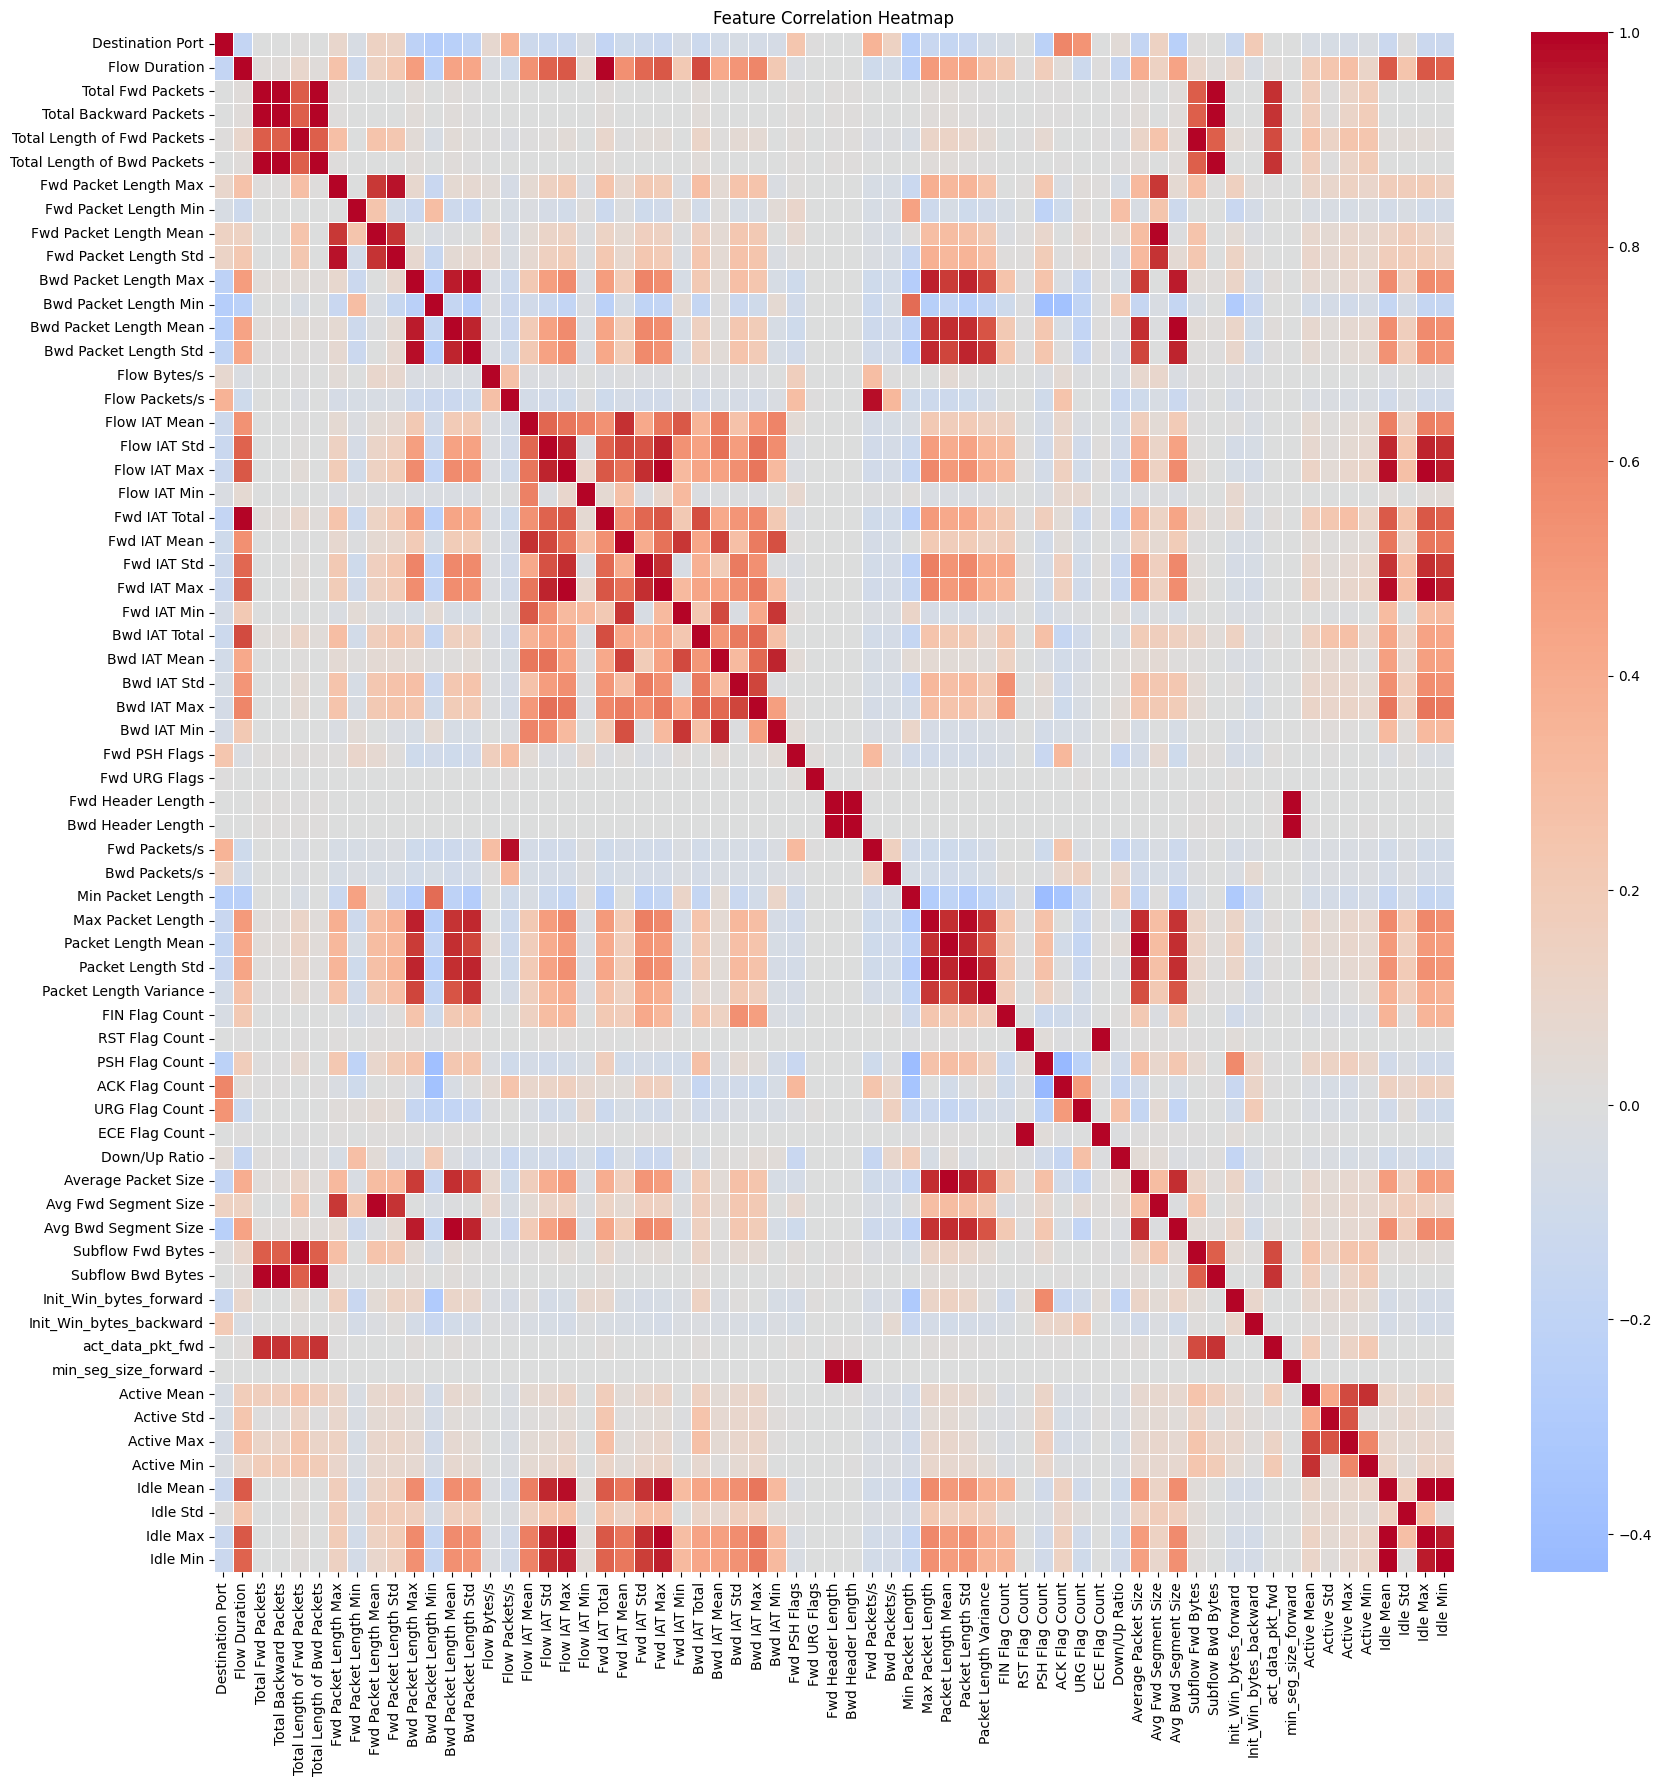

In [46]:
# Correlation Analysis:
numeric_features, categorical_features = get_feature_types(data)
high_corr = correlation_analysis(data, numeric_features)

In [47]:
# Printing the pairs with high correlation and isolating the near/perfect multicollinearity
high_multicollinearity = []
for item in high_corr:
    print(f'{item[0]} has a high correlation with {item[1]}: {item[2].round(4)}')
    if item[2] >= 0.95:
        high_multicollinearity.append(item)

Flow Duration has a high correlation with Fwd IAT Total: 0.9986
Total Fwd Packets has a high correlation with Total Backward Packets: 0.9998
Total Fwd Packets has a high correlation with Total Length of Bwd Packets: 0.9998
Total Fwd Packets has a high correlation with Subflow Bwd Bytes: 0.9998
Total Fwd Packets has a high correlation with act_data_pkt_fwd: 0.9059
Total Backward Packets has a high correlation with Total Length of Bwd Packets: 0.9999
Total Backward Packets has a high correlation with Subflow Bwd Bytes: 0.9999
Total Backward Packets has a high correlation with act_data_pkt_fwd: 0.9026
Total Length of Fwd Packets has a high correlation with Subflow Fwd Bytes: 1.0
Total Length of Bwd Packets has a high correlation with Subflow Bwd Bytes: 1.0
Total Length of Bwd Packets has a high correlation with act_data_pkt_fwd: 0.9027
Fwd Packet Length Max has a high correlation with Fwd Packet Length Mean: 0.8854
Fwd Packet Length Max has a high correlation with Fwd Packet Length Std: 0

In [49]:
# Removal of columns based on correlation analysis
selected_columns = ['Total Backward Packets', 'Total Length of Bwd Packets', 'Subflow Bwd Bytes', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size']

# dropping columns with perfect/near perfect multicollinearity
data.drop(columns=selected_columns, inplace=True)

In [50]:
# Updating the variables and checking dataset shape
numeric_features, categorical_features = get_feature_types(data)
data.shape

(2520914, 61)

## 3.3. Outliers

Outlier detection plays a crucial role in ensuring the quality and reliability of a dataset. Identifying features with significant deviations from the norm can help improve model accuracy by preventing skewed results.

<Figure size 1500x1000 with 0 Axes>

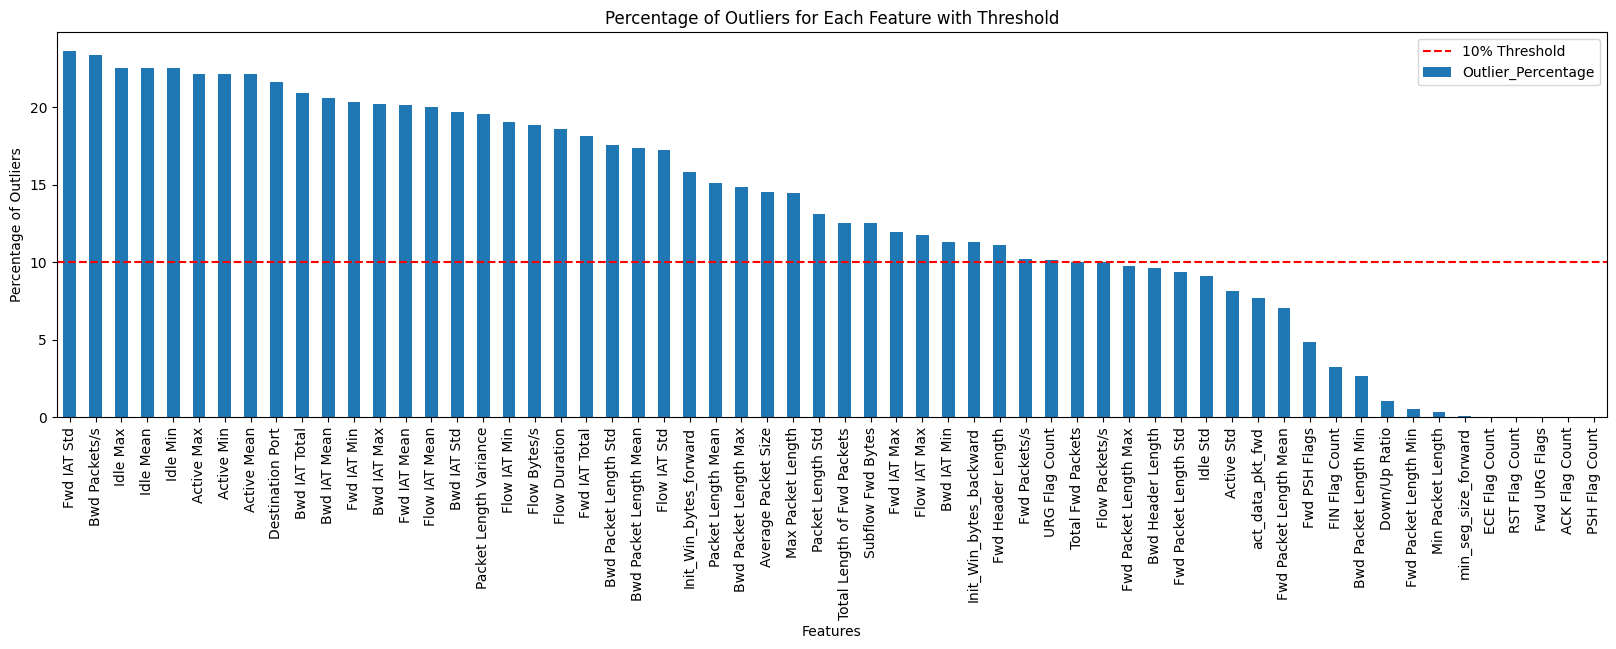

In [51]:
# Calculate outliers percentage
outlier_percentages = calculate_outliers_percentage(data[numeric_features])

# Convert to DataFrame for easier manipulation
outliers_df = pd.DataFrame.from_dict(outlier_percentages, orient='index', columns=['Outlier_Percentage'])

# Define the threshold for concern
threshold = 10

# Identify features with high percentage of outliers
high_outlier_features = outliers_df[outliers_df['Outlier_Percentage'] > threshold]

# Plot the outlier percentages and highlight features above the threshold
plt.figure(figsize=(15, 10))
outliers_df.sort_values(by='Outlier_Percentage', ascending=False).plot(kind='bar', legend=False, figsize=(20, 5))
plt.axhline(y=threshold, color='r', linestyle='--', label=f'{threshold}% Threshold')
plt.xlabel('Features')
plt.ylabel('Percentage of Outliers')
plt.title('Percentage of Outliers for Each Feature with Threshold')
plt.legend()
plt.show()

In [52]:
# Print the features with high outlier percentages
print(f"Features with outlier percentage above {threshold}%:\n")
print(high_outlier_features.sort_values('Outlier_Percentage', ascending=False))

# Cleaning up
del outliers_df

Features with outlier percentage above 10%:

                             Outlier_Percentage
Fwd IAT Std                           23.657570
Bwd Packets/s                         23.401512
Idle Mean                             22.500054
Idle Min                              22.500054
Idle Max                              22.500054
Active Max                            22.166484
Active Mean                           22.166484
Active Min                            22.166484
Destination Port                      21.644570
Bwd IAT Total                         20.925466
Bwd IAT Mean                          20.601575
Fwd IAT Min                           20.366066
Bwd IAT Max                           20.186964
Fwd IAT Mean                          20.125954
Flow IAT Mean                         19.985926
Bwd IAT Std                           19.700236
Packet Length Variance                19.539104
Flow IAT Min                          19.071853
Flow Bytes/s                          18.84

## 3.4. Data Distribution

Understanding the distribution of the data is fundamental for selecting the right preprocessing and modeling techniques. Data distribution also gives insights towards the best statistic tests to perform.

In [53]:
norm_dist = 0
not_norm_dist = 0

# Sample for efficient Anderson-Darling normality testing
sample_norm = data.sample(min(len(data), 50000), random_state=42)

for col in numeric_features:

    # Perform Anderson-Darling test for normality
    result = stats.anderson(sample_norm[col], dist='norm')

    # Compare the statistic with the critical value at 5% significance level
    if result.statistic < result.critical_values[2]:  # 5% significance level
        norm_dist += 1
    else:
        not_norm_dist += 1

print(f'{norm_dist} features are normally distributed')
print(f'{not_norm_dist} features are not normally distributed - Reject null hypothesis')


0 features are normally distributed
60 features are not normally distributed - Reject null hypothesis


## 3.5. Class Imbalance

In [54]:
# Count occurrences of each attack type and convert to a DataFrame
attack_counts_df = data['Attack Type'].value_counts().reset_index()
attack_counts_df.columns = ['Attack Type', 'Number of Occurrences']

# Counting the total for each attack on both cases
total_occurrences = attack_counts_df['Number of Occurrences'].sum()

# Calculating the respective percentages
attack_counts_df['% of Total'] = ((attack_counts_df['Number of Occurrences'] / total_occurrences) * 100).round(2)

print(attack_counts_df)

      Attack Type  Number of Occurrences  % of Total
0  Normal Traffic                2095220       83.11
1             DoS                 193745        7.69
2            DDoS                 128014        5.08
3   Port Scanning                  90694        3.60
4     Brute Force                   9150        0.36
5     Web Attacks                   2143        0.09
6            Bots                   1948        0.08


**Class Imbalance**

The previous analysis show a clear class imbalance, which should be taken into consideration while working with the CIC-IDS-2017, as highlighted by Panigrahi and Borah (2018).

**Observations**:
1. Dominance of the 'BENIGN' class/ Normal Traffic – 83.1% of the entire dataset
2. Higher types with lower counts – Even DoS, the second most relevant class, shows low counts
3. Rare classes even after regrouping, such as Bots, Web Attacks and Brute Force

**Potential implications**:
* Model Bias: Models can become biased towards the majority class, leading to high accuracy but poor recall and precision for minority classes.
* Performance Metrics: In an imbalanced dataset, accuracy is often not a sufficient metric to evaluate model performance. F1-score, precision, recall, or ROC-AUC are better suited for assessing the model's ability to classify different classes effectively.

**Ideas to address the issue during ML training**:
* Class weights to penalize mistakes on minority classes
* Ensemble Methods can improve overall predictions (Random Forests, XGBoost)
* Cross-validation with representative folds
* Partial SMOTE to help balancing the distribution
* Undersampling the majority class

In [55]:
# Cleaning up
del attack_counts_df

# 5. Feature Importance

Before conducting an analysis of feature importance, some characteristics of the dataset must be gathered. We already know it does not follow a Gaussian distribution and has a high presence of outliers. The next step is to evaluate its variance to determine the best statistical test.

In [56]:
# Applying the Levene's Test
# p-value < 0.05 suggests unequal variances among groups (rejecting the null hypothesis of equal variances)
variance_result = analyze_variance_homogeneity(data, numeric_features)

Not enough valid groups to perform Levene's test for feature: Fwd URG Flags
Not enough valid groups to perform Levene's test for feature: RST Flag Count
Not enough valid groups to perform Levene's test for feature: ECE Flag Count


In [57]:
# Analysing the results
no_significant_results = True

for feature, result in variance_result.items():   
    if result['p-value'] > 0.05:  
        print(f"\nFeature: {feature}")  
        print(f"  - Test Statistic: {result['Statistic']:.4f}")  
        print(f"  - p-value: {result['p-value']:.4f}")  
        print("  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).")  
        no_significant_results = False

# If no features had p-values > 0.05  
if no_significant_results:  
    print("\nNo features have p-values greater than 0.05. All features have significant differences in variance.")


Feature: Total Fwd Packets
  - Test Statistic: 0.6558
  - p-value: 0.6855
  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).

Feature: Fwd Header Length
  - Test Statistic: 0.0423
  - p-value: 0.9997
  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).

Feature: Bwd Header Length
  - Test Statistic: 0.0431
  - p-value: 0.9997
  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).

Feature: act_data_pkt_fwd
  - Test Statistic: 0.4443
  - p-value: 0.8495
  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).

Feature: min_seg_size_forward
  - Test Statistic: 0.0594
  - p-value: 0.9810
  - Interpretation: The variances are not significantly different (fail to reject null hypothesis).

Feature: Active Std
  - Test Statistic: 1.0386
  - p-value: 0.3082
  - Interpretation: The variances are not significantly

The above evaluation (only 3 features failed to reject the null hypothesis), together with the information about distribution, invalidates the use of One-Way ANOVA. A better fit, therefore, is the Kruskal-Wallis test, which is a non-parametric alternative that does not assume equal variances and is robust to the violations of normality or homoscedasticity.

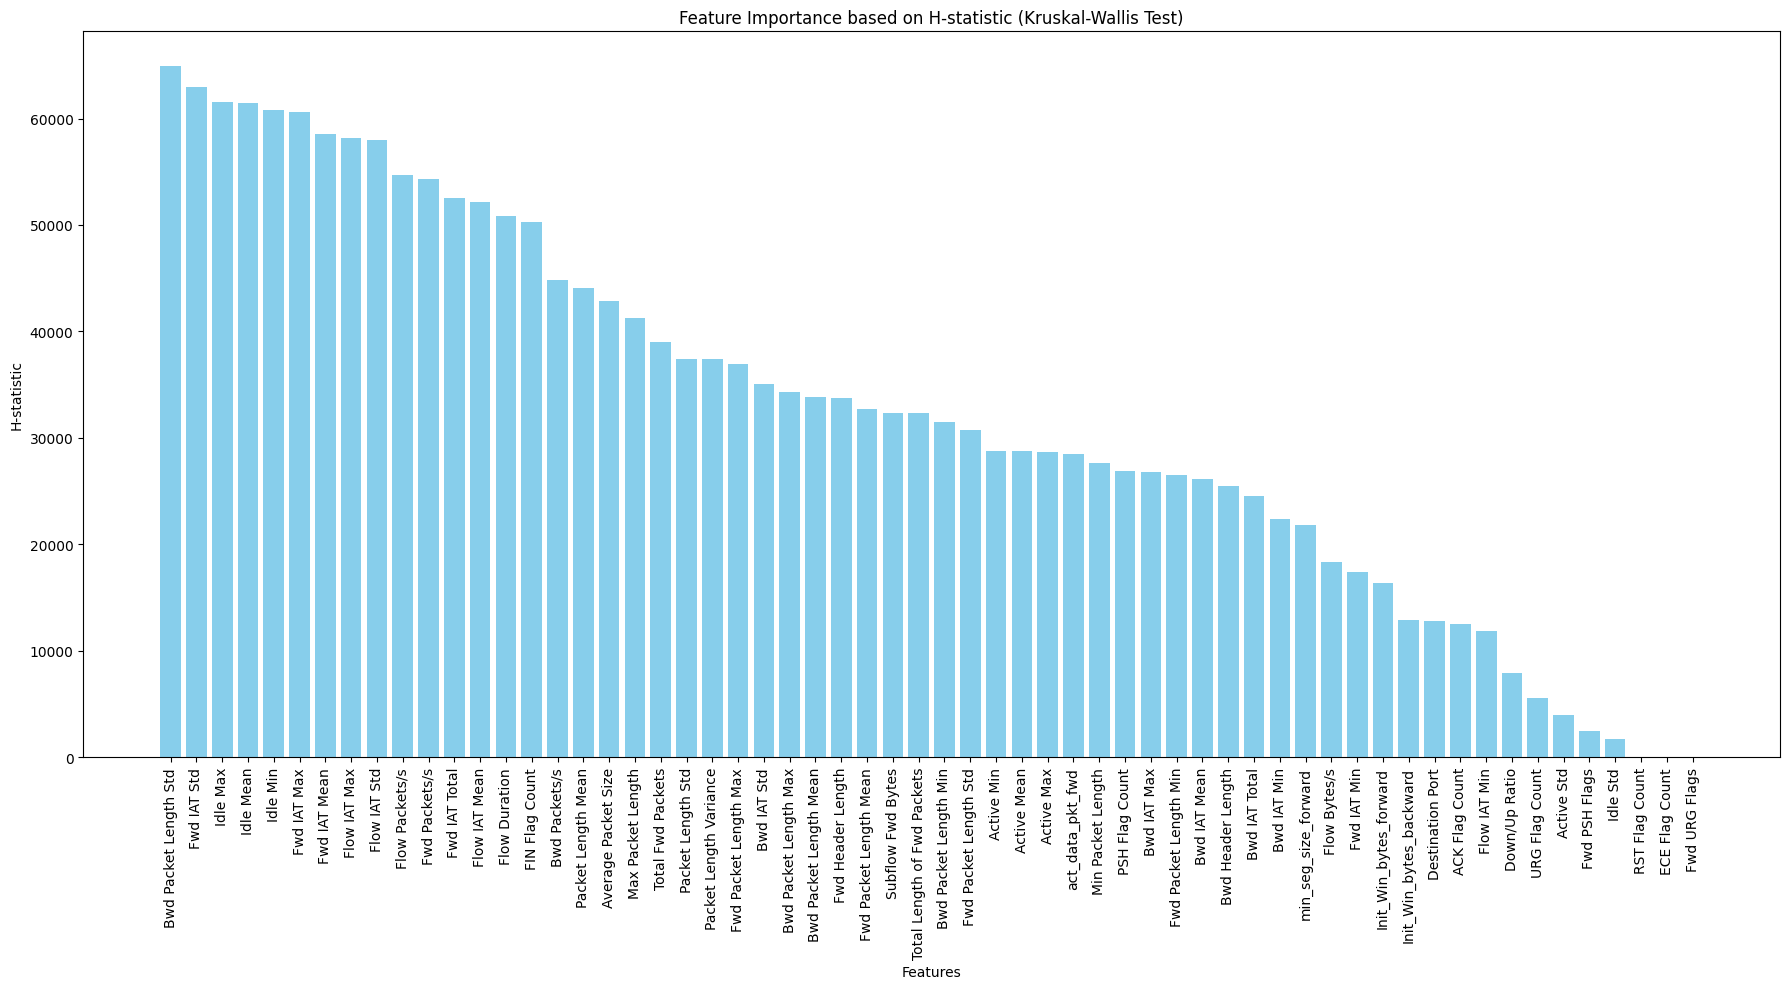

In [58]:
# Analysing feature importance using Kruskal-Wallis.
h_p_stats = analyze_feature_importance(data, numeric_features)

Now that we have the results from the Kruskal-Wallis test, we will train a Random Forest model and analyze its feature importance scores. This will provide an additional perspective on feature relevance, which we can then compare to the rankings obtained from the Kruskal-Wallis test.

Cross-Validation Score: 0.9981 ± 0.0000

Classification Report:

                precision    recall  f1-score   support

          Bots       0.84      0.55      0.67        58
   Brute Force       1.00      0.99      0.99       278
          DDoS       1.00      1.00      1.00      3799
           DoS       1.00      0.99      1.00      5758
Normal Traffic       1.00      1.00      1.00     62342
 Port Scanning       0.99      0.99      0.99      2701
   Web Attacks       1.00      0.89      0.94        64

      accuracy                           1.00     75000
     macro avg       0.98      0.92      0.94     75000
  weighted avg       1.00      1.00      1.00     75000




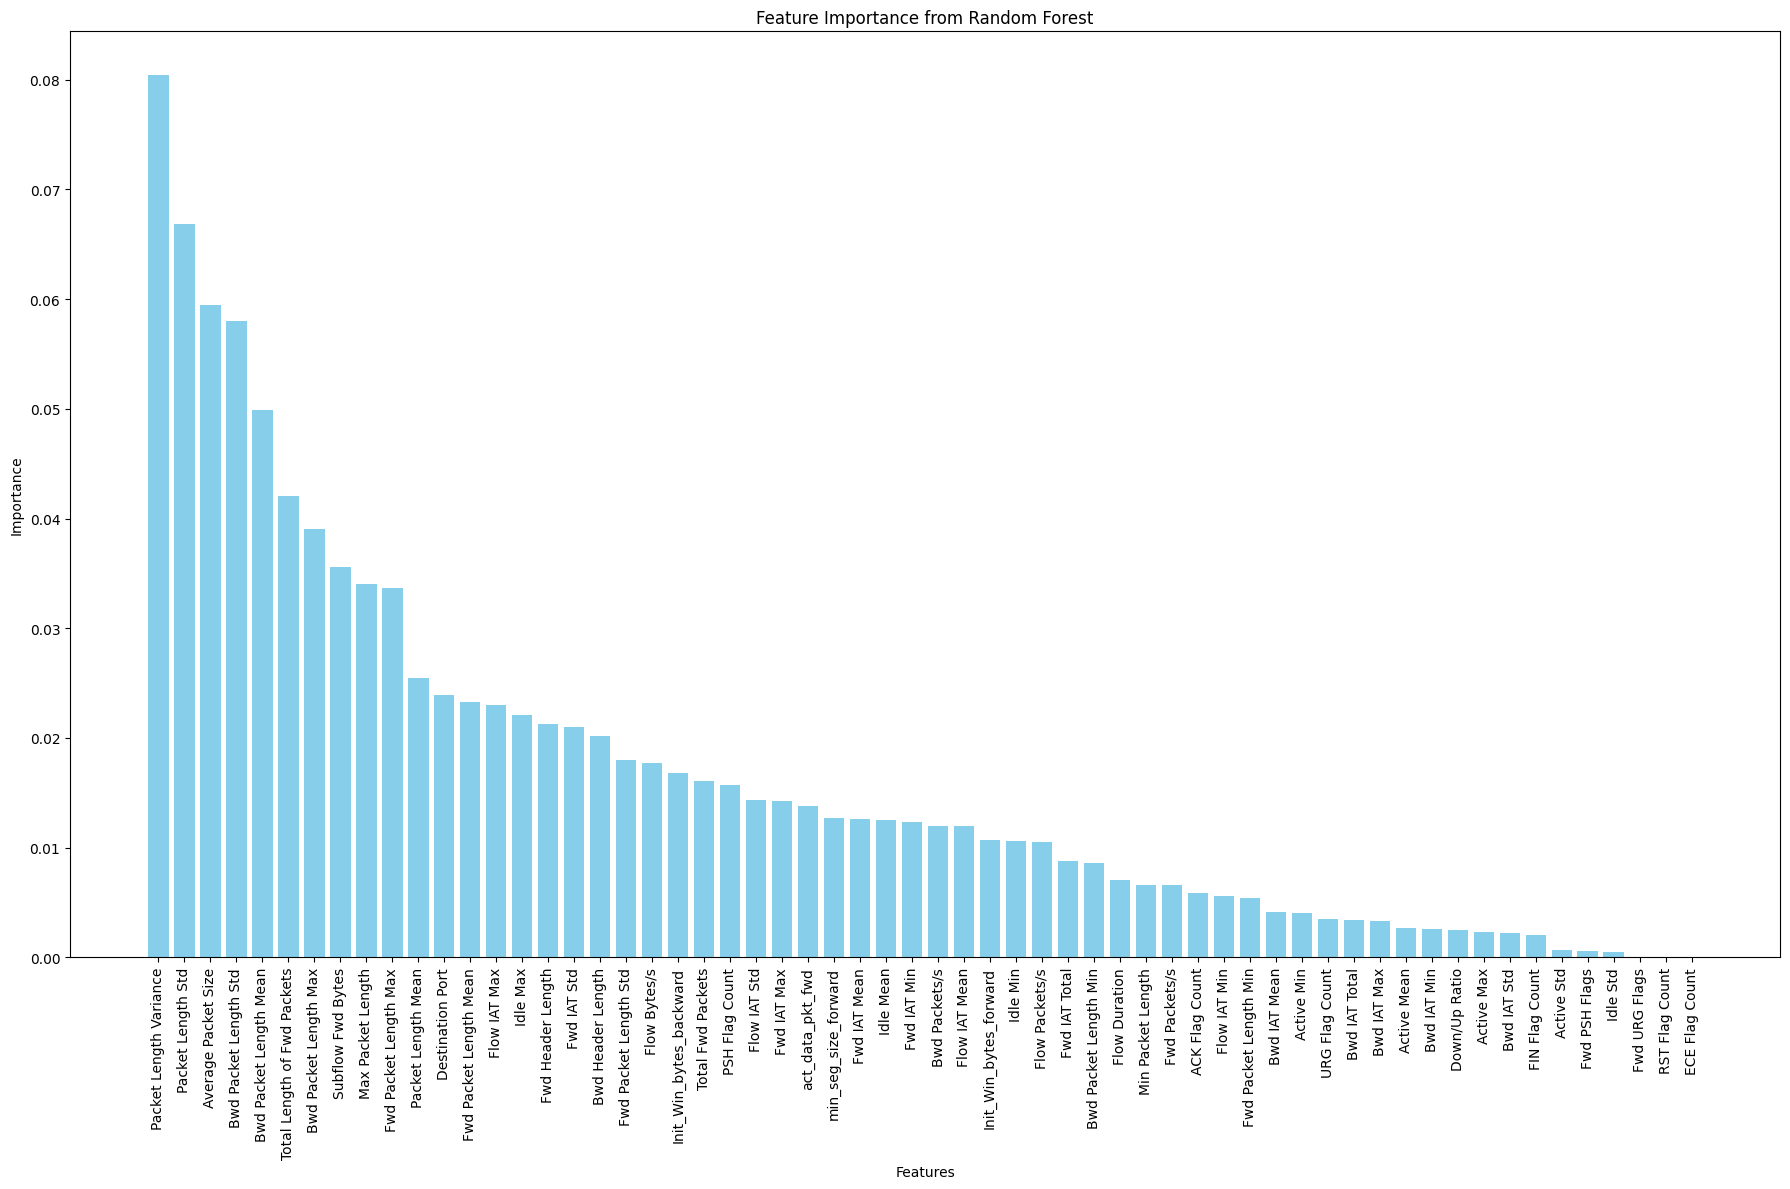

In [62]:
# Analysing feature importance using Tree-Model
feature_importance_tree, cm, rf_labels, cv_scores = analyze_feature_importance_rf(data, numeric_features)

Random Forests, being ensemble methods, offer a built-in mechanism for assessing feature importance. This importance is calculated based on how much each feature contributes to decreasing impurity (e.g., Gini impurity or entropy) within the decision trees of the forest. Features used higher up in the trees or in more trees of the forest for making splits are considered more important as they contribute more significantly to the model's predictive performance.

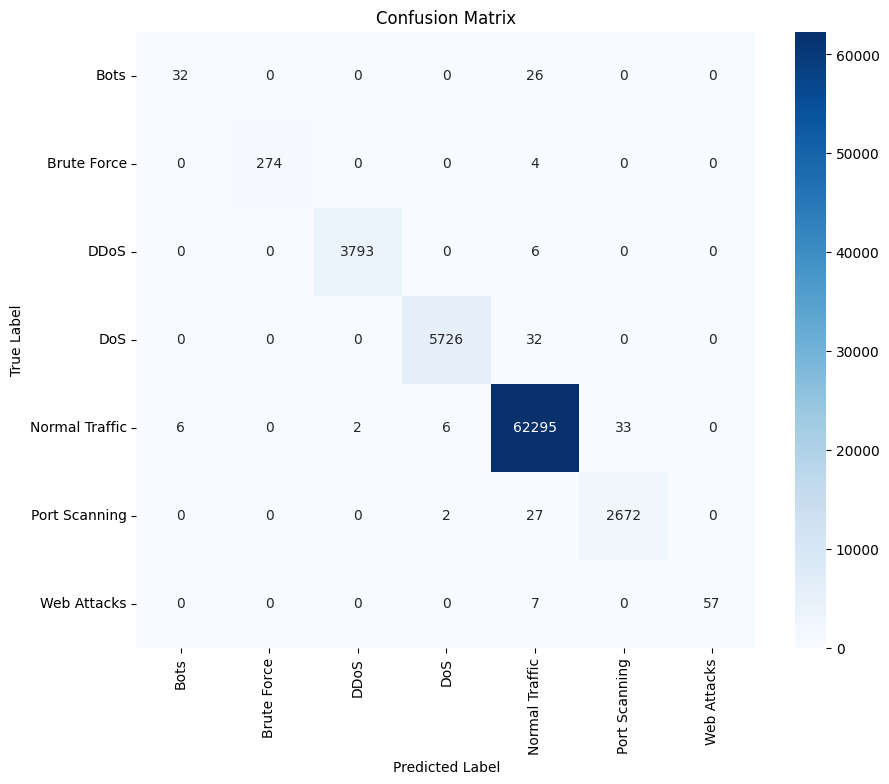

In [63]:
# Evaluating RF performance based on selected features
# Plot the confusion matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=rf_labels, yticklabels=rf_labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

After evaluating the Random Forest model's performance, we observe an overall positive result, indicating its suitability for feature importance analysis. However, the confusion matrix and the classification report reveal a notable weakness in classifying Bot attacks, with roughly 1/4 of these instances being misclassified as normal traffic (which is not surprising, considering this is a minority class). This misclassification highlights a potential area for improvement in our final intrusion detection model, which could be explored by considering more sophisticated bot detection methods, specialized feature engineering, and data balancing techniques. Despite this limitation, the overall performance justifies using the Random Forest's feature importance scores as a valuable reference for comparison with the Kruskal-Wallis H-statistic in our subsequent feature selection process.

In [64]:
# Preparing the df for comparison
h_p_stats.reset_index(inplace = True)
h_p_stats.rename(columns = {'index':'Feature'}, inplace = True)

# Sorting the new df for easier visualization
comparison_tb = feature_importance_tree.merge(h_p_stats, on = 'Feature', how = 'left')
comparison_tb_sorted = comparison_tb.sort_values(by='Importance', ascending=False)
comparison_tb_sorted

,Feature,Importance,H-statistic,p-value
0,Packet Length Variance,8.039872e-02,37396.986785,0.000000
1,Packet Length Std,6.681944e-02,37398.317881,0.000000
2,Average Packet Size,5.947074e-02,42846.624527,0.000000
3,Bwd Packet Length Std,5.798494e-02,64946.799982,0.000000
4,Bwd Packet Length Mean,4.986727e-02,33846.867744,0.000000
5,Total Length of Fwd Packets,4.207911e-02,32367.968240,0.000000
6,Bwd Packet Length Max,3.904192e-02,34318.956765,0.000000
7,Subflow Fwd Bytes,3.556409e-02,32367.968240,0.000000
8,Max Packet Length,3.402847e-02,41276.494095,0.000000
9,Fwd Packet Length Max,3.365990e-02,36932.406108,0.000000


# Outputs

In [67]:
# Clean dataset to a CSV file
data.to_csv('cicids2017_cleaned.csv', index=False)